# Calculate annual, seasonal, and monthly mean of KPPHBL

In [21]:
import numpy as np
import xarray as xr
from MITgcmutils import mds
path_scratch = '/scratch/jczhang/'
path_low = 'MITgcm_baroclinic_instability_old/MITgcm/verification/tutorial_reentrant_channel/run/'
start_iter = 2332800
delta_iter = 432
iters = np.arange(start_iter, start_iter + 360*delta_iter, delta_iter)

T_list = []

for it in iters:
    T = read_mitgcm._ocean_var(path_scratch + path_low, "T", it, ("k","j","i"))
    T_list.append(T)

T_all = xr.concat(T_list, dim="time")

# Assign iteration index as coordinate
T_all = T_all.assign_coords(time=("time", iters))

# Now compute annual mean
T_annual = T_all.mean(dim="time")

out_nc = "T_annual_low_FK.nc"
T_annual.name = "T"  # give it a variable name inside the file
T_annual.to_netcdf(out_nc, engine="h5netcdf")
print("saved:", out_nc)

saved: T_annual_low_FK.nc


In [1]:
import numpy as np
import xarray as xr
from MITgcmutils import mds
path_scratch = '/scratch/jczhang/'
path_low = 'MITgcm_50km_withoutGM/verification/tutorial_reentrant_channel/run/'
start_iter = 2332800
delta_iter = 432
iters = np.arange(start_iter, start_iter + 360*delta_iter, delta_iter)

kpphbl_list = []

for it in iters:
    diagMXL = mds.rdmds(path_scratch + path_low + 'Diags/' +'DiagMXL_2d', it)
    kpphbl = xr.DataArray(diagMXL[1, :,:], dims = ("j","i"), name = "kpphbl")
    print(it)
    kpphbl_list.append(kpphbl)

kpphbl_all = xr.concat(kpphbl_list, dim="time")

# Assign iteration index as coordinate
kpphbl_all = kpphbl_all.assign_coords(time=("time", iters))

# Now compute annual mean
kpphbl_annual = kpphbl_all.mean(dim="time")

out_nc = "kpphbl_annual_low_withoutGM.nc"
kpphbl_annual.name = "kpphbl"  # give it a variable name inside the file
kpphbl_annual.to_netcdf(out_nc, engine="h5netcdf")
print("saved:", out_nc)

2332800
2333232
2333664


KeyboardInterrupt: 

In [ ]:
import numpy as np
import xarray as xr
from MITgcmutils import mds

path_scratch = '/scratch/jczhang/'
path_low = 'MITgcm_50km_withoutGM/verification/tutorial_reentrant_channel/run/'
start_iter = 2332800
delta_iter = 432

# 360 days, daily output
iters = np.arange(start_iter, start_iter + 360*delta_iter, delta_iter)

kpphbl_list = []
for it in iters:
    diagMXL = mds.rdmds(path_scratch + path_low + 'Diags/' + 'DiagMXL_2d', it)
    kpphbl = xr.DataArray(diagMXL[1, :, :], dims=("j", "i"), name="kpphbl")
    print(it)
    kpphbl_list.append(kpphbl)

# Stack into time series: (time, j, i)
kpphbl_all = xr.concat(kpphbl_list, dim="time").assign_coords(time=("time", iters))
# SAVE the full daily time series too
out_nc_all = "kpphbl_daily_low_withoutGM.nc"
kpphbl_all.name = "kpphbl"
kpphbl_all.to_netcdf(out_nc_all, engine="h5netcdf")
print("saved:", out_nc_all, "shape:", kpphbl_all.shape)

# --- seasonal mean: 4 seasons, each 90 days (3 months * 30 days) ---
n_seasons = 4
days_per_season = 90
expected = n_seasons * days_per_season

if kpphbl_all.sizes["time"] != expected:
    raise ValueError(f"Expected {expected} timesteps (360 days), got {kpphbl_all.sizes['time']}")

# reshape time -> (season, day_in_season)
kpphbl_seasonal = (
    kpphbl_all
    .isel(time=slice(0, expected))
    .data.reshape(n_seasons, days_per_season, kpphbl_all.sizes["j"], kpphbl_all.sizes["i"])
)

# wrap back to xarray with coords
season_names = ["DJF", "MAM", "JJA", "SON"]  # rename if your model-year starts elsewhere
kpphbl_seasonal = xr.DataArray(
    kpphbl_seasonal.mean(axis=1),   # mean over 90 days
    dims=("season", "j", "i"),
    coords={"season": season_names,
            "j": kpphbl_all["j"],
            "i": kpphbl_all["i"]},
    name="kpphbl"
)

# Save
out_nc = "kpphbl_seasonal_low_withoutGM.nc"
kpphbl_seasonal.to_netcdf(out_nc, engine="h5netcdf")
print("saved:", out_nc, "shape:", kpphbl_seasonal.shape)  # should be (4, 120, 60)

2332800
2333232
2333664
2334096
2334528
2334960
2335392
2335824
2336256


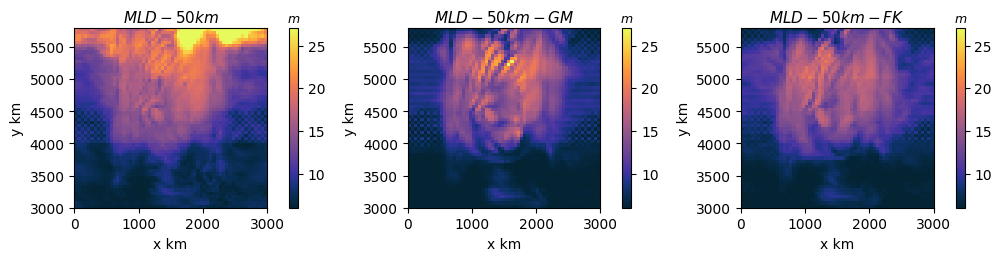

In [6]:
# Comparison of annual mean kpphbl 
# MITgcm_50km
# MITgcm_50km_FK
# path issue
import sys
from pathlib import Path
sys.path.insert(0, str(Path("/scratch/jczhang/submeso_data_driven").resolve()))

# check the velocity field and vorticity field
import numpy as np
import xarray as xr
from src.utils import read_mitgcm
from src.utils import build_coarse_grid
from src.utils import wT_total
from src.utils import wT
from src.utils import make_grid
from src.utils import coarsen_UVWTS
from src.utils import mld_avg
import importlib
importlib.reload(wT_total)
importlib.reload(wT)
from matplotlib.colors import TwoSlopeNorm
from matplotlib.colors import Normalize
import cmocean.cm as cmo
import h5netcdf

from MITgcmutils import mds
import matplotlib.pyplot as plt
path_scratch = '/scratch/jczhang/'
path_low = 'MITgcm_50km/verification/tutorial_reentrant_channel/run/'
# grid parameters
ds_50 = read_mitgcm.read_mitgrid_staggered(path_scratch + path_low)
# data
ds_low_withoutGM = xr.open_dataset("./kpphbl_daily_low_withoutGM.nc", engine="h5netcdf")
ds_low_withoutGM = ds_low_withoutGM["kpphbl"].mean(dim="time")
ds_low = xr.open_dataset("./kpphbl_annual_low.nc", engine="h5netcdf")
ds_low_FK = xr.open_dataset("./kpphbl_annual_low_FK.nc", engine="h5netcdf")

def sym_limits(Z, q = 0.995):
    v = np.nanquantile(np.abs(Z), q)
    return float(v)

def pos_limits(Z, q=0.995):
    v = np.nanquantile(Z, q)
    return float(v)

def range_limits(Z, q = 0.995):
    """Return (vmin, vmax) from lower/upper quantiles."""
    vmin = np.nanquantile(Z, 1 - q)   # e.g. 0.5% if q=0.995
    vmax = np.nanquantile(Z, q)       # e.g. 99.5%
    return float(vmin), float(vmax)

# plot 
XC = ds_50["XC"][60:116,:]
YC = ds_50["YC"][60:116,:]
fields = {
    r"$MLD-50km$":         {"Z": ds_low_withoutGM[60:116,:],  "units": r"$m$",  "kind": "positive", "cmap": cmo.thermal, "XC": XC/1e3, "YC":YC/1e3},
    r"$MLD-50km-GM$":         {"Z": ds_low["kpphbl"][60:116,:],  "units": r"$m$",  "kind": "positive", "cmap": cmo.thermal, "XC": XC/1e3, "YC":YC/1e3},
    r"$MLD-50km-FK$":         {"Z": ds_low_FK["kpphbl"][60:116,:],  "units": r"$m$",  "kind": "positive", "cmap": cmo.thermal, "XC": XC/1e3, "YC":YC/1e3},
}     



# Compute norms/limits per field
for key, meta in fields.items():   
    Z = meta["Z"]
    if meta["kind"] == "signed":
        q = sym_limits(Z)
        meta["norm"] = TwoSlopeNorm(vcenter=0.0, vmin=-q, vmax=+q)
    elif meta["kind"] == "positive":
        vmin, vmax = range_limits(Z)
        meta["norm"] = Normalize(vmin=vmin, vmax=vmax)
    elif meta["kind"] == "seq":
        meta["norm"] = Normalize(vmin=np.nanmin(Z), vmax=np.nanmax(Z))
    else:
        meta["norm"] = None
vmin, vmax = range_limits(ds_low["kpphbl"][60:116,:], q=1)  # <-- your function
shared_norm = Normalize(vmin=vmin, vmax=vmax)

# Plot: 2×5
fig, axes = plt.subplots(1,3, figsize=(10, 2.5), constrained_layout=True)
# --- dynamic number of panels ---
n_fields = len(fields)
# if only one panel
if n_fields == 1:
    axes = np.array([axes])
axes = axes.ravel()

for ax, (title, meta) in zip(axes, fields.items()):
    Z = meta["Z"]
    cmap = meta["cmap"]
    # norm = meta["norm"]
    norm = shared_norm
    XX = meta["XC"]
    YY = meta["YC"]
    pc = ax.pcolormesh(XX[:, :], YY[:, :], Z[:, :], shading='auto', cmap=cmap, norm=norm)
    ax.set_aspect('equal', adjustable='box')
    ax.set_title(title, fontsize=11, pad=4)
    ax.set_xlabel('x km'); ax.set_ylabel('y km')
    cb = fig.colorbar(pc, ax=ax, pad=0.02)
    cb.ax.set_title(meta["units"], pad=4, fontsize=9)
fig.savefig("./kpphbl_annual.png")
plt.show()

=== Annual FK - CTRL ===
Mean difference: 0.2740680043387507
Variance difference: 2.0162425057704403
Max difference: 5.439631683296627
Min difference: -13.383698316415153


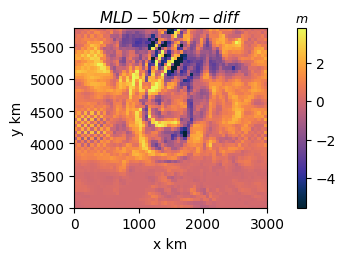

In [23]:
ds_ann_ctrl = xr.open_dataset("./kpphbl_annual_low.nc", engine="h5netcdf")
ds_ann_fk = xr.open_dataset("./kpphbl_annual_low_FK.nc", engine="h5netcdf")
h_ann_ctrl = ds_ann_ctrl["kpphbl"][60:116,:]
h_ann_fk   = ds_ann_fk["kpphbl"][60:116,:]

dh_ann = h_ann_fk - h_ann_ctrl

mean_ann = dh_ann.mean(dim=("j","i"))
var_ann  = dh_ann.var(dim=("j","i"))
max_ann  = dh_ann.max(dim=("j","i"))
min_ann  = dh_ann.min(dim=("j","i"))

print("=== Annual FK - CTRL ===")
print("Mean difference:", float(mean_ann.values))
print("Variance difference:", float(var_ann.values))
print("Max difference:", float(max_ann.values))
print("Min difference:", float(min_ann.values))
# Comparison of annual mean kpphbl 
# MITgcm_50km
# MITgcm_50km_FK
# path issue
import sys
from pathlib import Path
sys.path.insert(0, str(Path("/scratch/jczhang/submeso_data_driven").resolve()))

# check the velocity field and vorticity field
import numpy as np
import xarray as xr
from matplotlib.colors import TwoSlopeNorm
from matplotlib.colors import Normalize
import cmocean.cm as cmo
import h5netcdf

from MITgcmutils import mds
import matplotlib.pyplot as plt
path_scratch = '/scratch/jczhang/'
path_low = 'MITgcm_50km/verification/tutorial_reentrant_channel/run/'
# grid parameters
ds_50 = read_mitgcm.read_mitgrid_staggered(path_scratch + path_low)

def sym_limits(Z, q = 0.995):
    v = np.nanquantile(np.abs(Z), q)
    return float(v)

def pos_limits(Z, q=0.995):
    v = np.nanquantile(Z, q)
    return float(v)

def range_limits(Z, q = 0.995):
    """Return (vmin, vmax) from lower/upper quantiles."""
    vmin = np.nanquantile(Z, 1 - q)   # e.g. 0.5% if q=0.995
    vmax = np.nanquantile(Z, q)       # e.g. 99.5%
    return float(vmin), float(vmax)

# plot 
XC = ds_50["XC"][60:116,:]
YC = ds_50["YC"][60:116,:]
fields = {
    r"$MLD-50km-diff$":         {"Z": dh_ann,  "units": r"$m$",  "kind": "positive", "cmap": cmo.thermal, "XC": XC/1e3, "YC":YC/1e3},
}     



# Compute norms/limits per field
for key, meta in fields.items():   
    Z = meta["Z"]
    if meta["kind"] == "signed":
        q = sym_limits(Z)
        meta["norm"] = TwoSlopeNorm(vcenter=0.0, vmin=-q, vmax=+q)
    elif meta["kind"] == "positive":
        vmin, vmax = range_limits(Z)
        meta["norm"] = Normalize(vmin=vmin, vmax=vmax)
    elif meta["kind"] == "seq":
        meta["norm"] = Normalize(vmin=np.nanmin(Z), vmax=np.nanmax(Z))
    else:
        meta["norm"] = None
vmin, vmax = range_limits(ds_low["kpphbl"][60:116,:], q=1)  # <-- your function
shared_norm = Normalize(vmin=vmin, vmax=vmax)

# Plot: 2×5
fig, axes = plt.subplots(1,1, figsize=(7, 2.5), constrained_layout=True)
# --- dynamic number of panels ---
n_fields = len(fields)
# if only one panel
if n_fields == 1:
    axes = np.array([axes])
axes = axes.ravel()

for ax, (title, meta) in zip(axes, fields.items()):
    Z = meta["Z"]
    cmap = meta["cmap"]
    norm = meta["norm"]
    # norm = shared_norm
    XX = meta["XC"]
    YY = meta["YC"]
    pc = ax.pcolormesh(XX[:, :], YY[:, :], Z[:, :], shading='auto', cmap=cmap, norm=norm)
    ax.set_aspect('equal', adjustable='box')
    ax.set_title(title, fontsize=11, pad=4)
    ax.set_xlabel('x km'); ax.set_ylabel('y km')
    cb = fig.colorbar(pc, ax=ax, pad=0.02)
    cb.ax.set_title(meta["units"], pad=4, fontsize=9)
fig.savefig("./kpphbl_annual_diff.png")
plt.show()

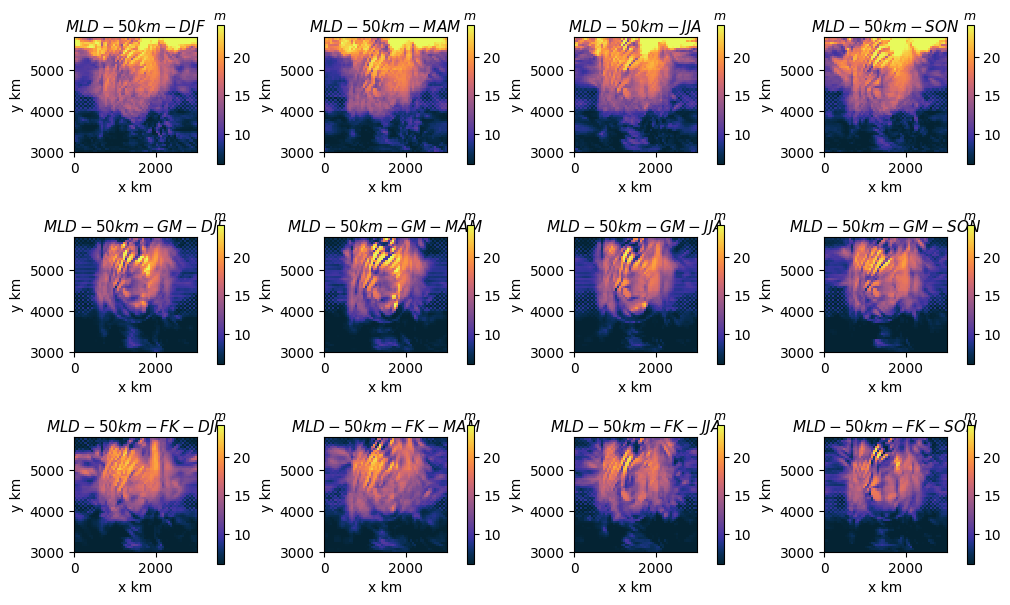

In [9]:
# Comparison of seasonal mean kpphbl 
# MITgcm_50km
# MITgcm_50km_FK
# path issue
import sys
from pathlib import Path
sys.path.insert(0, str(Path("/scratch/jczhang/submeso_data_driven").resolve()))

# check the velocity field and vorticity field
import numpy as np
import xarray as xr
from src.utils import read_mitgcm
from src.utils import build_coarse_grid
from src.utils import wT_total
from src.utils import wT
from src.utils import make_grid
from src.utils import coarsen_UVWTS
from src.utils import mld_avg
import importlib
importlib.reload(wT_total)
importlib.reload(wT)
from matplotlib.colors import TwoSlopeNorm
from matplotlib.colors import Normalize
import cmocean.cm as cmo
import h5netcdf

from MITgcmutils import mds
import matplotlib.pyplot as plt

path_low = 'MITgcm_50km/verification/tutorial_reentrant_channel/run/'
# grid parameters
ds_50 = read_mitgcm.read_mitgrid_staggered(path_scratch + path_low)
# data
ds_low_withoutGM = xr.open_dataset("./kpphbl_seasonal_low_withoutGM.nc", engine="h5netcdf")
ds_low = xr.open_dataset("./kpphbl_seasonal_low.nc", engine="h5netcdf")
ds_low_FK = xr.open_dataset("./kpphbl_seasonal_low_FK.nc", engine="h5netcdf")

def sym_limits(Z, q = 0.995):
    v = np.nanquantile(np.abs(Z), q)
    return float(v)

def pos_limits(Z, q=0.995):
    v = np.nanquantile(Z, q)
    return float(v)

def range_limits(Z, q = 0.995):
    """Return (vmin, vmax) from lower/upper quantiles."""
    vmin = np.nanquantile(Z, 1 - q)   # e.g. 0.5% if q=0.995
    vmax = np.nanquantile(Z, q)       # e.g. 99.5%
    return float(vmin), float(vmax)

# plot 
XC = ds_50["XC"][60:116,:]
YC = ds_50["YC"][60:116,:]
fields = {
    r"$MLD-50km-DJF$":         {"Z": ds_low_withoutGM["kpphbl"][0,60:116,:],  "units": r"$m$",  "kind": "positive", "cmap": cmo.thermal, "XC": XC/1e3, "YC":YC/1e3},
    r"$MLD-50km-MAM$":         {"Z": ds_low_withoutGM["kpphbl"][1,60:116,:],  "units": r"$m$",  "kind": "positive", "cmap": cmo.thermal, "XC": XC/1e3, "YC":YC/1e3},
    r"$MLD-50km-JJA$":         {"Z": ds_low_withoutGM["kpphbl"][2,60:116,:],  "units": r"$m$",  "kind": "positive", "cmap": cmo.thermal, "XC": XC/1e3, "YC":YC/1e3},
    r"$MLD-50km-SON$":         {"Z": ds_low_withoutGM["kpphbl"][3,60:116,:],  "units": r"$m$",  "kind": "positive", "cmap": cmo.thermal, "XC": XC/1e3, "YC":YC/1e3},
    r"$MLD-50km-GM-DJF$":         {"Z": ds_low["kpphbl"][0,60:116,:],  "units": r"$m$",  "kind": "positive", "cmap": cmo.thermal, "XC": XC/1e3, "YC":YC/1e3},
    r"$MLD-50km-GM-MAM$":         {"Z": ds_low["kpphbl"][1,60:116,:],  "units": r"$m$",  "kind": "positive", "cmap": cmo.thermal, "XC": XC/1e3, "YC":YC/1e3},
    r"$MLD-50km-GM-JJA$":         {"Z": ds_low["kpphbl"][2,60:116,:],  "units": r"$m$",  "kind": "positive", "cmap": cmo.thermal, "XC": XC/1e3, "YC":YC/1e3},
    r"$MLD-50km-GM-SON$":         {"Z": ds_low["kpphbl"][3,60:116,:],  "units": r"$m$",  "kind": "positive", "cmap": cmo.thermal, "XC": XC/1e3, "YC":YC/1e3},
    r"$MLD-50km-FK-DJF$":         {"Z": ds_low_FK["kpphbl"][0,60:116,:],  "units": r"$m$",  "kind": "positive", "cmap": cmo.thermal, "XC": XC/1e3, "YC":YC/1e3},
    r"$MLD-50km-FK-MAM$":         {"Z": ds_low_FK["kpphbl"][1,60:116,:],  "units": r"$m$",  "kind": "positive", "cmap": cmo.thermal, "XC": XC/1e3, "YC":YC/1e3},
    r"$MLD-50km-FK-JJA$":         {"Z": ds_low_FK["kpphbl"][2,60:116,:],  "units": r"$m$",  "kind": "positive", "cmap": cmo.thermal, "XC": XC/1e3, "YC":YC/1e3},
    r"$MLD-50km-FK-SON$":         {"Z": ds_low_FK["kpphbl"][3,60:116,:],  "units": r"$m$",  "kind": "positive", "cmap": cmo.thermal, "XC": XC/1e3, "YC":YC/1e3},
}     


vmin, vmax = range_limits(ds_low["kpphbl"][2,60:116,:], q=1)  # <-- your function
shared_norm = Normalize(vmin=vmin, vmax=vmax)

# Compute norms/limits per field
for key, meta in fields.items():   
    Z = meta["Z"]
    if meta["kind"] == "signed":
        q = sym_limits(Z)
        meta["norm"] = TwoSlopeNorm(vcenter=0.0, vmin=-q, vmax=+q)
    elif meta["kind"] == "positive":
        vmin, vmax = range_limits(Z)
        meta["norm"] = Normalize(vmin=vmin, vmax=vmax)
    elif meta["kind"] == "seq":
        meta["norm"] = Normalize(vmin=np.nanmin(Z), vmax=np.nanmax(Z))
    else:
        meta["norm"] = None



# Plot: 2×5
fig, axes = plt.subplots(3,4, figsize=(10, 6), constrained_layout=True)
# --- dynamic number of panels ---
n_fields = len(fields)
# if only one panel
if n_fields == 1:
    axes = np.array([axes])
axes = axes.ravel()

for ax, (title, meta) in zip(axes, fields.items()):
    Z = meta["Z"]
    cmap = meta["cmap"]
    # norm = meta["norm"]
    norm = shared_norm
    XX = meta["XC"]
    YY = meta["YC"]
    pc = ax.pcolormesh(XX[:, :], YY[:, :], Z[:, :], shading='auto', cmap=cmap, norm=norm)
    ax.set_aspect('equal', adjustable='box')
    ax.set_title(title, fontsize=11, pad=4)
    ax.set_xlabel('x km'); ax.set_ylabel('y km')
    cb = fig.colorbar(pc, ax=ax, pad=0.02)
    cb.ax.set_title(meta["units"], pad=4, fontsize=9)
fig.savefig("./kpphbl_seasonal.png")
plt.show()


=== Seasonal FK - CTRL ===
Season 0:
  Mean difference: 0.8203016686518356
  Variance difference: 5.376924275968808
  Max difference: 10.039765887790256
  Min difference: -15.099672990375096
Season 1:
  Mean difference: 0.4419247015443428
  Variance difference: 6.179046131367217
  Max difference: 12.20549003813002
  Min difference: -25.453298568725582
Season 2:
  Mean difference: 0.24204820392150728
  Variance difference: 4.209952794923711
  Max difference: 10.988773239983452
  Min difference: -10.563365968068439
Season 3:
  Mean difference: -0.40800255676268266
  Variance difference: 5.010501599740941
  Max difference: 9.383931552039254
  Min difference: -14.56075759993659


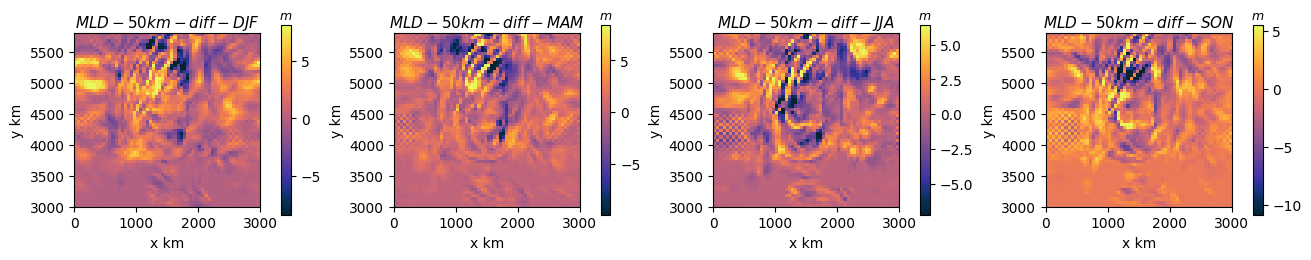

In [26]:
ds_sea_ctrl = xr.open_dataset("./kpphbl_seasonal_low.nc", engine="h5netcdf")
ds_sea_fk = xr.open_dataset("./kpphbl_seasonal_low_FK.nc", engine="h5netcdf")
h_sea_ctrl = ds_sea_ctrl["kpphbl"][:,60:116,:]
h_sea_fk   = ds_sea_fk["kpphbl"][:,60:116,:]

dh_sea = h_sea_fk - h_sea_ctrl

mean_sea = dh_sea.mean(dim=("j","i"))
var_sea  = dh_sea.var(dim=("j","i"))
max_sea  = dh_sea.max(dim=("j","i"))
min_sea  = dh_sea.min(dim=("j","i"))

print("\n=== Seasonal FK - CTRL ===")
for s in range(4):
    print(f"Season {s}:")
    print("  Mean difference:", float(mean_sea[s].values))
    print("  Variance difference:", float(var_sea[s].values))
    print("  Max difference:", float(max_sea[s].values))
    print("  Min difference:", float(min_sea[s].values))
import numpy as np
import xarray as xr
from matplotlib.colors import TwoSlopeNorm
from matplotlib.colors import Normalize
import cmocean.cm as cmo
import h5netcdf

from MITgcmutils import mds
import matplotlib.pyplot as plt
path_scratch = '/scratch/jczhang/'
path_low = 'MITgcm_50km/verification/tutorial_reentrant_channel/run/'
# grid parameters
ds_50 = read_mitgcm.read_mitgrid_staggered(path_scratch + path_low)

def sym_limits(Z, q = 0.995):
    v = np.nanquantile(np.abs(Z), q)
    return float(v)

def pos_limits(Z, q=0.995):
    v = np.nanquantile(Z, q)
    return float(v)

def range_limits(Z, q = 0.995):
    """Return (vmin, vmax) from lower/upper quantiles."""
    vmin = np.nanquantile(Z, 1 - q)   # e.g. 0.5% if q=0.995
    vmax = np.nanquantile(Z, q)       # e.g. 99.5%
    return float(vmin), float(vmax)

# plot 
XC = ds_50["XC"][60:116,:]
YC = ds_50["YC"][60:116,:]
fields = {
    r"$MLD-50km-diff-DJF$":         {"Z": dh_sea[0,:,:],  "units": r"$m$",  "kind": "positive", "cmap": cmo.thermal, "XC": XC/1e3, "YC":YC/1e3},
    r"$MLD-50km-diff-MAM$":         {"Z": dh_sea[1,:,:],  "units": r"$m$",  "kind": "positive", "cmap": cmo.thermal, "XC": XC/1e3, "YC":YC/1e3},
    r"$MLD-50km-diff-JJA$":         {"Z": dh_sea[2,:,:],  "units": r"$m$",  "kind": "positive", "cmap": cmo.thermal, "XC": XC/1e3, "YC":YC/1e3},
    r"$MLD-50km-diff-SON$":         {"Z": dh_sea[3,:,:],  "units": r"$m$",  "kind": "positive", "cmap": cmo.thermal, "XC": XC/1e3, "YC":YC/1e3},
}     



# Compute norms/limits per field
for key, meta in fields.items():   
    Z = meta["Z"]
    if meta["kind"] == "signed":
        q = sym_limits(Z)
        meta["norm"] = TwoSlopeNorm(vcenter=0.0, vmin=-q, vmax=+q)
    elif meta["kind"] == "positive":
        vmin, vmax = range_limits(Z)
        meta["norm"] = Normalize(vmin=vmin, vmax=vmax)
    elif meta["kind"] == "seq":
        meta["norm"] = Normalize(vmin=np.nanmin(Z), vmax=np.nanmax(Z))
    else:
        meta["norm"] = None
vmin, vmax = range_limits(ds_low["kpphbl"][60:116,:], q=1)  # <-- your function
shared_norm = Normalize(vmin=vmin, vmax=vmax)

# Plot: 2×5
fig, axes = plt.subplots(1,4, figsize=(13, 2.5), constrained_layout=True)
# --- dynamic number of panels ---
n_fields = len(fields)
# if only one panel
if n_fields == 1:
    axes = np.array([axes])
axes = axes.ravel()

for ax, (title, meta) in zip(axes, fields.items()):
    Z = meta["Z"]
    cmap = meta["cmap"]
    norm = meta["norm"]
    # norm = shared_norm
    XX = meta["XC"]
    YY = meta["YC"]
    pc = ax.pcolormesh(XX[:, :], YY[:, :], Z[:, :], shading='auto', cmap=cmap, norm=norm)
    ax.set_aspect('equal', adjustable='box')
    ax.set_title(title, fontsize=11, pad=4)
    ax.set_xlabel('x km'); ax.set_ylabel('y km')
    cb = fig.colorbar(pc, ax=ax, pad=0.02)
    cb.ax.set_title(meta["units"], pad=4, fontsize=9)
fig.savefig("./kpphbl_season_diff.png")
plt.show()

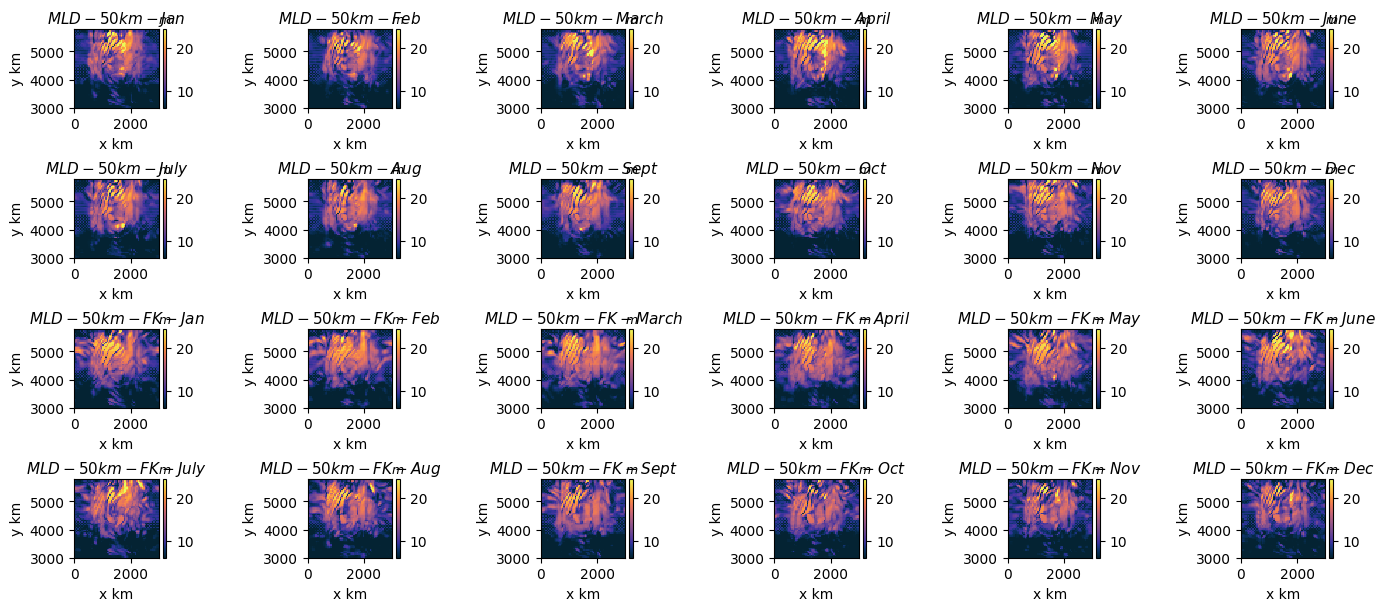

In [15]:
# Comparison of seasonal mean kpphbl 
# MITgcm_50km
# MITgcm_50km_FK
# path issue
import sys
from pathlib import Path
sys.path.insert(0, str(Path("/scratch/jczhang/submeso_data_driven").resolve()))

# check the velocity field and vorticity field
import numpy as np
import xarray as xr
from src.utils import read_mitgcm
from src.utils import build_coarse_grid
from src.utils import wT_total
from src.utils import wT
from src.utils import make_grid
from src.utils import coarsen_UVWTS
from src.utils import mld_avg
import importlib
importlib.reload(wT_total)
importlib.reload(wT)
from matplotlib.colors import TwoSlopeNorm
from matplotlib.colors import Normalize
import cmocean.cm as cmo
import h5netcdf

from MITgcmutils import mds
import matplotlib.pyplot as plt

path_low = 'MITgcm_50km/verification/tutorial_reentrant_channel/run/'
# grid parameters
ds_50 = read_mitgcm.read_mitgrid_staggered(path_scratch + path_low)
# data

ds_low = xr.open_dataset("./kpphbl_monthly_low.nc", engine="h5netcdf")
ds_low_FK = xr.open_dataset("./kpphbl_monthly_low_FK.nc", engine="h5netcdf")

def sym_limits(Z, q = 0.995):
    v = np.nanquantile(np.abs(Z), q)
    return float(v)

def pos_limits(Z, q=0.995):
    v = np.nanquantile(Z, q)
    return float(v)

def range_limits(Z, q = 0.995):
    """Return (vmin, vmax) from lower/upper quantiles."""
    vmin = np.nanquantile(Z, 1 - q)   # e.g. 0.5% if q=0.995
    vmax = np.nanquantile(Z, q)       # e.g. 99.5%
    return float(vmin), float(vmax)

# plot 
XC = ds_50["XC"][60:116,:]
YC = ds_50["YC"][60:116,:]
fields = {
    r"$MLD-50km-Jan$":         {"Z": ds_low["kpphbl"][0,60:116,:],  "units": r"$m$",  "kind": "positive", "cmap": cmo.thermal, "XC": XC/1e3, "YC":YC/1e3},
    r"$MLD-50km-Feb$":         {"Z": ds_low["kpphbl"][1,60:116,:],  "units": r"$m$",  "kind": "positive", "cmap": cmo.thermal, "XC": XC/1e3, "YC":YC/1e3},
    r"$MLD-50km-March$":         {"Z": ds_low["kpphbl"][2,60:116,:],  "units": r"$m$",  "kind": "positive", "cmap": cmo.thermal, "XC": XC/1e3, "YC":YC/1e3},
    r"$MLD-50km-April$":         {"Z": ds_low["kpphbl"][3,60:116,:],  "units": r"$m$",  "kind": "positive", "cmap": cmo.thermal, "XC": XC/1e3, "YC":YC/1e3},
    r"$MLD-50km-May$":         {"Z": ds_low["kpphbl"][4,60:116,:],  "units": r"$m$",  "kind": "positive", "cmap": cmo.thermal, "XC": XC/1e3, "YC":YC/1e3},
    r"$MLD-50km-June$":         {"Z": ds_low["kpphbl"][5,60:116,:],  "units": r"$m$",  "kind": "positive", "cmap": cmo.thermal, "XC": XC/1e3, "YC":YC/1e3},
    r"$MLD-50km-July$":         {"Z": ds_low["kpphbl"][6,60:116,:],  "units": r"$m$",  "kind": "positive", "cmap": cmo.thermal, "XC": XC/1e3, "YC":YC/1e3},
    r"$MLD-50km-Aug$":         {"Z": ds_low["kpphbl"][7,60:116,:],  "units": r"$m$",  "kind": "positive", "cmap": cmo.thermal, "XC": XC/1e3, "YC":YC/1e3},
    r"$MLD-50km-Sept$":         {"Z": ds_low["kpphbl"][8,60:116,:],  "units": r"$m$",  "kind": "positive", "cmap": cmo.thermal, "XC": XC/1e3, "YC":YC/1e3},
    r"$MLD-50km-Oct$":         {"Z": ds_low["kpphbl"][9,60:116,:],  "units": r"$m$",  "kind": "positive", "cmap": cmo.thermal, "XC": XC/1e3, "YC":YC/1e3},
    r"$MLD-50km-Nov$":         {"Z": ds_low["kpphbl"][10,60:116,:],  "units": r"$m$",  "kind": "positive", "cmap": cmo.thermal, "XC": XC/1e3, "YC":YC/1e3},
    r"$MLD-50km-Dec$":         {"Z": ds_low["kpphbl"][11,60:116,:],  "units": r"$m$",  "kind": "positive", "cmap": cmo.thermal, "XC": XC/1e3, "YC":YC/1e3},
    r"$MLD-50km-FK-Jan$":         {"Z": ds_low_FK["kpphbl"][0,60:116,:],  "units": r"$m$",  "kind": "positive", "cmap": cmo.thermal, "XC": XC/1e3, "YC":YC/1e3},
    r"$MLD-50km-FK-Feb$":         {"Z": ds_low_FK["kpphbl"][1,60:116,:],  "units": r"$m$",  "kind": "positive", "cmap": cmo.thermal, "XC": XC/1e3, "YC":YC/1e3},
    r"$MLD-50km-FK-March$":         {"Z": ds_low_FK["kpphbl"][2,60:116,:],  "units": r"$m$",  "kind": "positive", "cmap": cmo.thermal, "XC": XC/1e3, "YC":YC/1e3},
    r"$MLD-50km-FK-April$":         {"Z": ds_low_FK["kpphbl"][3,60:116,:],  "units": r"$m$",  "kind": "positive", "cmap": cmo.thermal, "XC": XC/1e3, "YC":YC/1e3},
    r"$MLD-50km-FK-May$":         {"Z": ds_low_FK["kpphbl"][4,60:116,:],  "units": r"$m$",  "kind": "positive", "cmap": cmo.thermal, "XC": XC/1e3, "YC":YC/1e3},
    r"$MLD-50km-FK-June$":         {"Z": ds_low_FK["kpphbl"][5,60:116,:],  "units": r"$m$",  "kind": "positive", "cmap": cmo.thermal, "XC": XC/1e3, "YC":YC/1e3},
    r"$MLD-50km-FK-July$":         {"Z": ds_low_FK["kpphbl"][6,60:116,:],  "units": r"$m$",  "kind": "positive", "cmap": cmo.thermal, "XC": XC/1e3, "YC":YC/1e3},
    r"$MLD-50km-FK-Aug$":         {"Z": ds_low_FK["kpphbl"][7,60:116,:],  "units": r"$m$",  "kind": "positive", "cmap": cmo.thermal, "XC": XC/1e3, "YC":YC/1e3},
    r"$MLD-50km-FK-Sept$":         {"Z": ds_low_FK["kpphbl"][8,60:116,:],  "units": r"$m$",  "kind": "positive", "cmap": cmo.thermal, "XC": XC/1e3, "YC":YC/1e3},
    r"$MLD-50km-FK-Oct$":         {"Z": ds_low_FK["kpphbl"][9,60:116,:],  "units": r"$m$",  "kind": "positive", "cmap": cmo.thermal, "XC": XC/1e3, "YC":YC/1e3},
    r"$MLD-50km-FK-Nov$":         {"Z": ds_low_FK["kpphbl"][10,60:116,:],  "units": r"$m$",  "kind": "positive", "cmap": cmo.thermal, "XC": XC/1e3, "YC":YC/1e3},
    r"$MLD-50km-FK-Dec$":         {"Z": ds_low_FK["kpphbl"][11,60:116,:],  "units": r"$m$",  "kind": "positive", "cmap": cmo.thermal, "XC": XC/1e3, "YC":YC/1e3},
}     


vmin, vmax = range_limits(ds_low["kpphbl"][2,60:116,:], q=0.995)  # <-- your function
shared_norm = Normalize(vmin=vmin, vmax=vmax)

# Compute norms/limits per field
for key, meta in fields.items():   
    Z = meta["Z"]
    if meta["kind"] == "signed":
        q = sym_limits(Z)
        meta["norm"] = TwoSlopeNorm(vcenter=0.0, vmin=-q, vmax=+q)
    elif meta["kind"] == "positive":
        vmin, vmax = range_limits(Z)
        meta["norm"] = Normalize(vmin=vmin, vmax=vmax)
    elif meta["kind"] == "seq":
        meta["norm"] = Normalize(vmin=np.nanmin(Z), vmax=np.nanmax(Z))
    else:
        meta["norm"] = None



# Plot: 2×5
fig, axes = plt.subplots(4,6, figsize=(14, 6), constrained_layout=True)
# --- dynamic number of panels ---
n_fields = len(fields)
# if only one panel
if n_fields == 1:
    axes = np.array([axes])
axes = axes.ravel()

for ax, (title, meta) in zip(axes, fields.items()):
    Z = meta["Z"]
    cmap = meta["cmap"]
    # norm = meta["norm"]
    norm = shared_norm
    XX = meta["XC"]
    YY = meta["YC"]
    pc = ax.pcolormesh(XX[:, :], YY[:, :], Z[:, :], shading='auto', cmap=cmap, norm=norm)
    ax.set_aspect('equal', adjustable='box')
    ax.set_title(title, fontsize=11, pad=4)
    ax.set_xlabel('x km'); ax.set_ylabel('y km')
    cb = fig.colorbar(pc, ax=ax, pad=0.02)
    cb.ax.set_title(meta["units"], pad=4, fontsize=9)
fig.savefig("./kpphbl_Monthly.png")
plt.show()

In [16]:
# High-resolution submesoscale heat flux
# ML_predicted submesoscale heat flux
# low-resolution submesoscale heat flux
# low resolution submesoscale heat flux with Fox Kemper parameterization

# path issue
import sys
from pathlib import Path
sys.path.insert(0, str(Path("/scratch/jczhang/submeso_data_driven").resolve()))

# check the velocity field and vorticity field
import numpy as np
import xarray as xr
from src.utils import read_mitgcm
from src.utils import build_coarse_grid
from src.utils import wT_total
from src.utils import wT
from src.utils import make_grid
from src.utils import coarsen_UVWTS
from src.utils import mld_avg
import importlib
importlib.reload(wT_total)
importlib.reload(wT)
from matplotlib.colors import TwoSlopeNorm
from matplotlib.colors import Normalize
import cmocean.cm as cmo
import h5netcdf

from MITgcmutils import mds
import matplotlib.pyplot as plt
# other parameters
path_scratch = '/scratch/jczhang/'
path_high = 'MITgcm_baroclinic_instability_old/MITgcm/verification/tutorial_reentrant_channel/run/'
path_low_FK = 'MITgcm_50km_FK/verification/tutorial_reentrant_channel/run/'
path_low = 'MITgcm_50km/verification/tutorial_reentrant_channel/run/'
# grid parameters
ds_50 = read_mitgcm.read_mitgrid_staggered(path_scratch + path_low)
# load the data
GM_diags = mds.rdmds(path_scratch + path_low_FK + 'Diags/' +'GM_diags', 2488320)
# kpphbl = xr.DataArray(diagMXL[1, :,:], dims = ("j","i"), name = "kpphbl")
psiX = GM_diags[0, ...]   # (k, j, i_g)  GM_PsiX
psiY = GM_diags[1, ...]   # (k, j_g, i)  GM_PsiY

# Wrap as DataArrays with correct dims/coords if you have them
PsiX = xr.DataArray(psiX, dims=("k","j","i_g"))
PsiY = xr.DataArray(psiY, dims=("k","j_g","i"))
# 
# 
dPsiY_dx = (PsiY.roll(i=-1, roll_coords=False) - PsiY) / ds_50["DXG"]
dPsiX_dy = (PsiX.shift(j=-1) - PsiX) / ds_50["DYG"]
# interp
grid = make_grid.make_grid_periodic_x(ds_50)
dPsiY_dx_c = grid.interp(dPsiY_dx, "Y", boundary="fill") 
dPsiX_dy_c = grid.interp(dPsiX_dy, "X", boundary="periodic")
# 
Wstar = (dPsiY_dx_c - dPsiX_dy_c)
rho0, cp = 1035.0, 3994.0
wT_annual_low = rho0 * cp * Wstar * T_annual

print(Wstar.shape)

(49, 120, 60)


In [ ]:
# High-resolution submesoscale heat flux
# ML_predicted submesoscale heat flux
# low-resolution submesoscale heat flux
# low resolution submesoscale heat flux with Fox Kemper parameterization

# path issue
import sys
from pathlib import Path
sys.path.insert(0, str(Path("/scratch/jczhang/submeso_data_driven").resolve()))

# check the velocity field and vorticity field
import numpy as np
import xarray as xr
from src.utils import read_mitgcm
from src.utils import build_coarse_grid
from src.utils import wT_total
from src.utils import wT
from src.utils import make_grid
from src.utils import coarsen_UVWTS
from src.utils import mld_avg
import importlib
importlib.reload(wT_total)
importlib.reload(wT)
from matplotlib.colors import TwoSlopeNorm
from matplotlib.colors import Normalize
import cmocean.cm as cmo
import h5netcdf

from MITgcmutils import mds
import matplotlib.pyplot as plt
# other parameters
path_scratch = '/scratch/jczhang/'
path_high = 'MITgcm_baroclinic_instability_old/MITgcm/verification/tutorial_reentrant_channel/run/'
path_low_FK = 'MITgcm_50km_FK/verification/tutorial_reentrant_channel/run/'
path_low = 'MITgcm_50km/verification/tutorial_reentrant_channel/run/'

# grid_dir = path_scratch + path_MITgcm
ds_fine_high = read_mitgcm.read_mitgrid_staggered(path_scratch + path_high)
ds_coarse_high = build_coarse_grid.build_coarse_grid_staggered(ds_fine_high,box_j=10, box_i=10)

ds_50 = read_mitgcm.read_mitgrid_staggered(path_scratch + path_low)
# 
# submesoscale heat flux
# high-resolution
box_j, box_i = 10, 10
W = read_mitgcm._ocean_var(path_scratch + path_high, "W", 14802912, ("k_l","j","i"))
T = read_mitgcm._ocean_var(path_scratch + path_high, "T", 14802912, ("k","j","i"))
W_c = coarsen_UVWTS.coarse_field("W", W, ds_fine_high, box_j, box_i)
T_c = coarsen_UVWTS.coarse_field("T", T, ds_fine_high, box_j, box_i)
diagMXL = mds.rdmds(path_scratch + path_high + 'Diags/' +'DiagMXL_2d', 14802912)
kpphbl = xr.DataArray(diagMXL[1, :,:], dims = ("j","i"), name = "kpphbl")
ds_ocean_c = xr.Dataset(dict(T = T_c, W = W_c))
ds_ocean = xr.Dataset(dict(T = T, W = W))
wT_high_sub, wT_high_total, wT_high_meso = wT.submeso_vertical_heat_flux(ds_fine_high, ds_coarse_high, ds_ocean, ds_ocean_c, box_j = 10, box_i = 10, boundary_Z = "fill", to_wm2 = True)

kpphbl_coarse = coarsen_UVWTS.coarse_field("kpphbl", kpphbl, ds_fine_high, box_j, box_i)
wT_high_sub = mld_avg.mld_avg(wT_high_sub, kpphbl_coarse, ds_coarse_high)
wT_high_total = mld_avg.mld_avg(wT_high_total, kpphbl_coarse, ds_coarse_high)
wT_high_meso = mld_avg.mld_avg(wT_high_meso, kpphbl_coarse, ds_coarse_high)
#  low resolution with foxkemper
W = read_mitgcm._ocean_var(path_scratch + path_low_FK, "W", 2376000, ("k_l","j","i"))
T = read_mitgcm._ocean_var(path_scratch + path_low_FK, "T", 2376000, ("k","j","i"))
diagMXL = mds.rdmds(path_scratch + path_low_FK + 'Diags/' +'DiagMXL_2d', 2376000)
kpphbl = xr.DataArray(diagMXL[1, :,:], dims = ("j","i"), name = "kpphbl")
ds_ocean = xr.Dataset(dict(T = T, W = W))
wT_low_FK = wT_total._vertical_heat_flux(ds_50,ds_ocean)
wT_low_FK = mld_avg.mld_avg(wT_low_FK, kpphbl, ds_50)
# low resolution 
W = read_mitgcm._ocean_var(path_scratch + path_low, "W", 2376000, ("k_l","j","i"))
T = read_mitgcm._ocean_var(path_scratch + path_low, "T", 2376000, ("k","j","i"))
diagMXL = mds.rdmds(path_scratch + path_low + 'Diags/' +'DiagMXL_2d', 2376000)
kpphbl = xr.DataArray(diagMXL[1, :,:], dims = ("j","i"), name = "kpphbl")
ds_ocean = xr.Dataset(dict(T = T, W = W))
wT_low = wT_total._vertical_heat_flux(ds_50,ds_ocean)
wT_low = mld_avg.mld_avg(wT_low, kpphbl, ds_50)
    
# limits function
def sym_limits(Z, q = 0.995):
    v = np.nanquantile(np.abs(Z), q)
    return float(v)

def pos_limits(Z, q=0.995):
    v = np.nanquantile(Z, q)
    return float(v)

def range_limits(Z, q = 0.995):
    """Return (vmin, vmax) from lower/upper quantiles."""
    vmin = np.nanquantile(Z, 1 - q)   # e.g. 0.5% if q=0.995
    vmax = np.nanquantile(Z, q)       # e.g. 99.5%
    return float(vmin), float(vmax)

# plot 
XC = ds_50["XC"]
YC = ds_50["YC"]
fields = {
    r"$wT_{high-sub}$":         {"Z": wT_high_sub,  "units": r"$s^{-1}$",  "kind": "signed", "cmap": cmo.balance, "XC": XC/1e3, "YC":YC/1e3},
    r"$wT_{high-total}$":         {"Z": wT_high_total,  "units": r"$s^{-1}$",  "kind": "signed", "cmap": cmo.balance, "XC": XC/1e3, "YC":YC/1e3},
    r"$wT_{high_meso}$":         {"Z": wT_high_meso,  "units": r"$s^{-1}$",  "kind": "signed", "cmap": cmo.balance, "XC": XC/1e3, "YC":YC/1e3},
    r"$wT_{low}$":         {"Z": wT_low,  "units": r"$m s^{-1}$",  "kind": "signed", "cmap":cmo.balance, "XC": XC/1e3, "YC":YC/1e3},
    r"$wT_{low_FK}$":         {"Z": wT_low_FK,  "units": r"$m s^{-1}$",  "kind": "signed", "cmap":cmo.balance, "XC": XC/1e3, "YC":YC/1e3},
}     



# Compute norms/limits per field
for key, meta in fields.items():   
    Z = meta["Z"]
    if meta["kind"] == "signed":
        q = sym_limits(Z)
        meta["norm"] = TwoSlopeNorm(vcenter=0.0, vmin=-q, vmax=+q)
    elif meta["kind"] == "positive":
        vmin, vmax = range_limits(Z)
        meta["norm"] = Normalize(vmin=vmin, vmax=vmax)
    elif meta["kind"] == "seq":
        meta["norm"] = Normalize(vmin=np.nanmin(Z), vmax=np.nanmax(Z))
    else:
        meta["norm"] = None

# Plot: 2×5
fig, axes = plt.subplots(1,5, figsize=(10, 3), constrained_layout=True)
# --- dynamic number of panels ---
n_fields = len(fields)
# if only one panel
if n_fields == 1:
    axes = np.array([axes])
axes = axes.ravel()

for ax, (title, meta) in zip(axes, fields.items()):
    Z = meta["Z"]
    cmap = meta["cmap"]
    norm = meta["norm"]
    XX = meta["XC"]
    YY = meta["YC"]
    pc = ax.pcolormesh(XX[:, :], YY[:, :], Z[:, :], shading='auto', cmap=cmap, norm=norm)
    ax.set_aspect('equal', adjustable='box')
    ax.set_title(title, fontsize=11, pad=4)
    ax.set_xlabel('x km'); ax.set_ylabel('y km')
    cb = fig.colorbar(pc, ax=ax, pad=0.02)
    cb.ax.set_title(meta["units"], pad=4, fontsize=9)
fig.savefig("./viz_last.png")
plt.show()